In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/walmart_prepared.csv")
df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Store,Date,IsHoliday,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Margin,Lag_1,Lag_2,Lag_4,Lag_12,Rolling_4w,Rolling_12w,Year,Month,Week
0,1,2010-02-05,0,1.0,24924.50,42.31,2.572,0.0,0.0,0.0,...,0.12,NaN,NaN,NaN,NaN,NaN,NaN,2010,2,5
1,1,2010-02-05,0,26.0,11737.12,42.31,2.572,0.0,0.0,0.0,...,0.12,24924.50,NaN,NaN,NaN,NaN,NaN,2010,2,5
2,1,2010-02-05,0,17.0,13223.76,42.31,2.572,0.0,0.0,0.0,...,0.12,11737.12,24924.50,NaN,NaN,NaN,NaN,2010,2,5
3,1,2010-02-05,0,45.0,37.44,42.31,2.572,0.0,0.0,0.0,...,0.12,13223.76,11737.12,NaN,NaN,12480.7050,NaN,2010,2,5
4,1,2010-02-05,0,28.0,1085.29,42.31,2.572,0.0,0.0,0.0,...,0.12,37.44,13223.76,24924.5,NaN,6520.9025,NaN,2010,2,5


In [4]:
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 28 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Date          421570 non-null  datetime64[ns]
 2   IsHoliday     421570 non-null  int64         
 3   Dept          421570 non-null  float64       
 4   Weekly_Sales  421570 non-null  float64       
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     421570 non-null  float64       
 8   MarkDown2     421570 non-null  float64       
 9   MarkDown3     421570 non-null  float64       
 10  MarkDown4     421570 non-null  float64       
 11  MarkDown5     421570 non-null  float64       
 12  CPI           421570 non-null  float64       
 13  Unemployment  421570 non-null  float64       
 14  Type          421570 non-null  int64         
 15  Size          421

,Store,Date,IsHoliday,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Margin,Lag_1,Lag_2,Lag_4,Lag_12,Rolling_4w,Rolling_12w,Year,Month,Week
count,421570.000000,421570,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,...,4.214970e+05,421569.000000,421568.000000,421566.000000,421558.000000,421567.000000,421559.000000,421570.000000,421570.000000,421570.000000
mean,22.200546,2011-06-18 08:30:31.963375360,0.070358,44.260317,15981.258123,60.090059,3.361027,2590.074819,879.974298,468.087665,...,1.200000e-01,15981.293478,15981.329685,15981.389393,15981.528973,15981.300528,15981.377966,2010.968591,6.449510,25.826762
min,1.000000,2010-02-05 00:00:00,0.000000,1.000000,-4988.940000,-2.060000,2.472000,0.000000,-265.760000,-29.100000,...,1.200000e-01,-4988.940000,-4988.940000,-4988.940000,-4988.940000,-56.535000,143.536667,2010.000000,1.000000,1.000000
25%,11.000000,2010-10-08 00:00:00,0.000000,18.000000,2079.650000,46.680000,2.933000,0.000000,0.000000,0.000000,...,1.200000e-01,2079.680000,2079.732500,2079.697500,2079.697500,6863.272500,9153.439167,2010.000000,4.000000,14.000000
50%,22.000000,2011-06-17 00:00:00,0.000000,37.000000,7612.030000,62.090000,3.452000,0.000000,0.000000,0.000000,...,1.200000e-01,7612.030000,7612.065000,7612.100000,7612.100000,12677.457500,14182.036667,2011.000000,6.000000,26.000000
75%,33.000000,2012-02-24 00:00:00,0.000000,74.000000,20205.852500,74.280000,3.738000,2809.050000,2.200000,4.540000,...,1.200000e-01,20205.860000,20205.935000,20206.085000,20206.182500,21517.767500,20886.730417,2012.000000,9.000000,38.000000
max,45.000000,2012-10-26 00:00:00,1.000000,99.000000,693099.360000,100.140000,4.468000,88646.760000,104519.540000,141630.610000,...,1.200000e-01,693099.360000,693099.360000,693099.360000,693099.360000,217224.065000,115695.292500,2012.000000,12.000000,52.000000
std,12.785297,NaN,0.255750,30.492054,22711.183519,18.447931,0.458515,6052.385934,5084.538801,5528.873453,...,7.067116e-13,22711.198855,22711.213625,22711.250898,22711.418293,12750.928887,9222.284505,0.796876,3.243217,14.151887


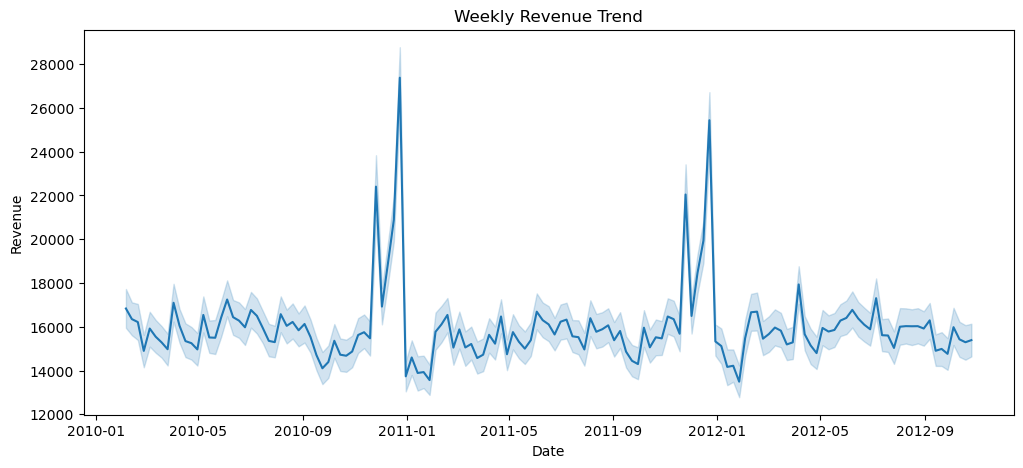

In [5]:
plt.figure(figsize=(12,5))
sns.lineplot(data=df, x="Date", y="Revenue")
plt.title("Weekly Revenue Trend")
plt.show()

In [6]:
df.groupby("Store")["Revenue"].sum().sort_values(ascending=False).head(10)

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
Name: Revenue, dtype: float64

In [7]:
df.groupby("Dept")["Revenue"].sum().sort_values(ascending=False).head(10)

Dept
92.0    4.839433e+08
95.0    4.493202e+08
38.0    3.931181e+08
72.0    3.057252e+08
90.0    2.910685e+08
40.0    2.889360e+08
2.0     2.806112e+08
91.0    2.167817e+08
13.0    1.973216e+08
8.0     1.942808e+08
Name: Revenue, dtype: float64

<Axes: xlabel='IsHoliday', ylabel='Revenue'>

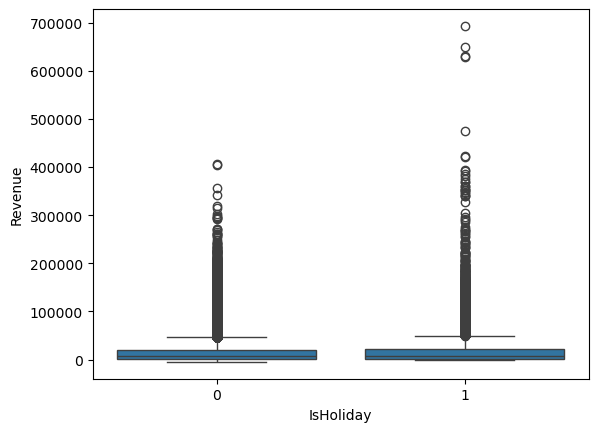

In [8]:
sns.boxplot(data=df, x="IsHoliday", y="Revenue")

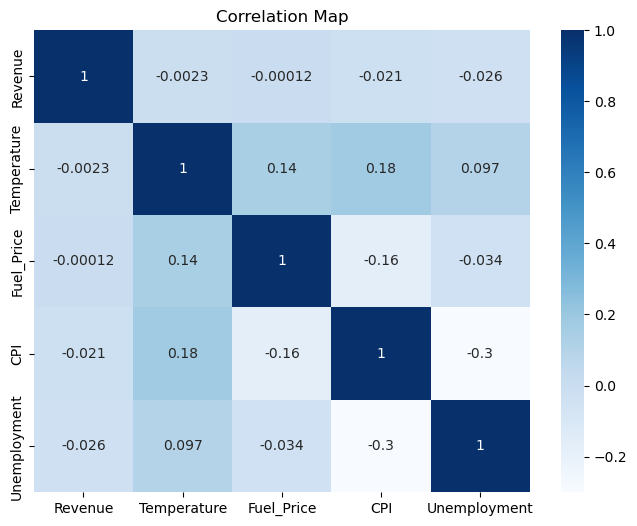

In [9]:
numeric = df[["Revenue","Temperature","Fuel_Price","CPI","Unemployment"]]

plt.figure(figsize=(8,6))
sns.heatmap(numeric.corr(), annot=True, cmap="Blues")
plt.title("Correlation Map")
plt.show()

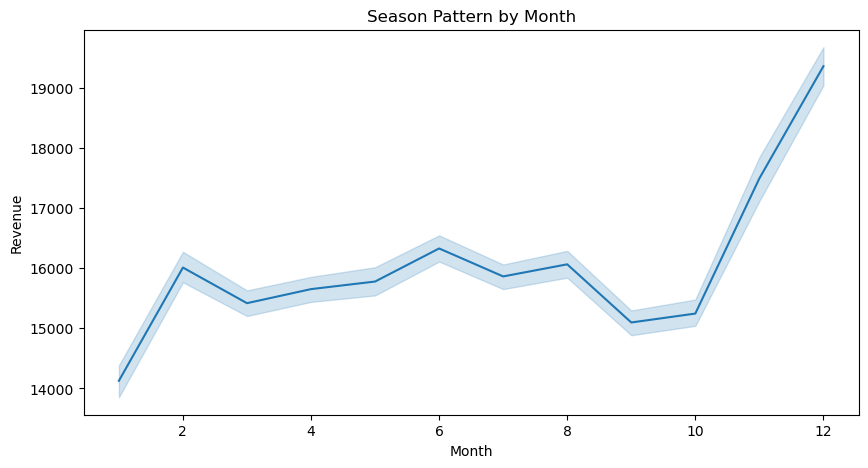

In [10]:
df["Month"] = df["Date"].dt.month

plt.figure(figsize=(10,5))
sns.lineplot(data=df, x="Month", y="Revenue")
plt.title("Season Pattern by Month")
plt.show()